# DSC 210 -- Exam 3 Takehome -- Spring 2026

Name: Jacob Bauer

---

**AI Use Policy:** You are permitted to use AI tools (ChatGPT, Copilot, etc.) on this exam. If you do, you must disclose this in each sub-problem where AI assisted you by noting which tool you used and briefly describing how. Using AI without disclosure, or submitting AI output without genuine engagement and reflection, does not satisfy the requirements of this exam.

## Problem 1 - Meningitis (40 points)

Meningitis is an inflammation of the meninges, the membranes surrounding the brain and spinal cord. It is often caused by infections with viruses or bacteria, and if left untreated, can cause serious harm to the brain and nervous system. Doctors hence treat it as an emergency and seek to immediately start treatment.

However, treating meningitis successfully requires knowing the cause of the infection. Bacterial meningitis, caused by infection with various kinds of bacteria, can be treated with appropriate antibiotics. But viral meningitis, which can be caused by several different kinds of virus, does not respond at all to antibiotics. It's common to immediately give antibiotics so treatment can start before the cause is definitively known. Doctors then use a lumbar puncture to draw a sample of cerebrospinal fluid (CSF), the fluid surrounding the brain and spine, to test for signs of bacteria. There are several diagnostic signs:

- Gram staining
- White blood cell count
- Glucose level
- Protein levels

These measurements are fairly fast and easy to get from a CSF sample, but are not definitive. To definitively show a bacterium is present, it must be cultured over several days, or antigens detected in a counterimmunoelectrophoresis test. To definitively prove viral meningitis, the virus must be isolated from blood, stool, or CSF samples, or all other causes must be ruled out. In either case, a definitive ruling takes much more time and effort, while a bacterial infection must be treated straight away.

**Can we accurately decide whether a patient has bacterial or viral meningitis using just the fast and easy-to-obtain test results?**

### Problem 1 - The Data

The data comes from a retrospective observational study at Duke University Medical Center, using records for all patients with acute meningitis between January 1969 and July 1980. The researchers used laboratory records to determine which patients had bacterial or viral meningitis, and extracted initial test results from the patients' charts. Patients had both blood tests and cerebrospinal fluid (CSF) tests. Most patients had tests conducted immediately upon admission, and some had a second set of tests later in their stay.

Many values are missing, as not every patient had every test conducted. Some features are present in the data but not documented; these are marked "Unknown". These undocumented features were not used in the original published analysis of the data.

**Feature Descriptions**
- `casenum`: Case number
- `year`: Year of the case (two digits, such as 78 for 1978)
- `month`: Month number
- `age`: Age of the patient, years
- `race`: Race of the patient (Black or White)
- `sex`: Sex of the patient (male or female)
- `dx`: Unknown
- `priordx`: Unknown
- `priorrx`: Whether patient received antibiotics prior to admission to the hospital (0 = no, 1 = yes)
- `wbc`: White blood cell count per 1,000, in a blood sample
- `pmn`: % polymorphonuclear leukocytes (PMNs) in blood
- `bands`: Percentage of blood PMNs that are immature "band" forms
- `compns`: Unknown
- `daysrx`: Unknown
- `offrx`: Unknown
- `lptodc`: Unknown
- `lpgap`: Hours between the first lumbar puncture and the second, if a second was conducted
- `morelabs`: Unknown
- `bloodgl`: Blood glucose level (mg/dL)
- `gl`: CSF glucose level (mg/dL)
- `pr`: CSF protein level (mg/dL)
- `reds`: CSF red blood cell count (count per mm³)
- `whites`: Total leukocytes (white blood cells) in CSF (count per mm³)
- `polys`: % polymorphonuclear leukocytes (PMNs) in CSF
- `lymphs`: Cerebrospinal fluid lymphocyte count (units not given)
- `monos`: Unknown; possibly CSF monocyte percentage
- `others`: Unknown; possibly percentage of other white blood cell types in CSF
- `gram`: Gram smear result (0 = Gram-negative, positive values mean Gram-positive)
- `culture`: Unknown
- `cie`: Unknown; possibly the result of counterimmunoelectrophoresis (CIE) tests for presence of specific bacterial antigens, but coding is not clear
- `bloodclt`: Unknown
- `bloodgl2`: Unknown; possibly blood glucose level at the time of the second lumbar puncture
- `gl2`: CSF glucose level in the second lumbar puncture
- `pr2`: CSF protein level in the second lumbar puncture
- `reds2`: CSF red blood cell count in the second lumbar puncture
- `whites2`: CSF white blood cell count in the second lumbar puncture
- `polys2`: % PMNs in the second lumbar puncture
- `lymphs2`: CSF lymphocyte count in the second lumbar puncture
- `monos2`: Unknown; possibly CSF monocyte percentage in the second lumbar puncture
- `others2`: Unknown; possibly percentage of other white blood cell types in the second lumbar puncture
- `sumbands`: Unknown
- `abm`: Whether the patient has acute bacterial meningitis (1) or viral meningitis (0), as ultimately determined by cultures and antigen tests

The data are split across several files:
1. `meningitis_intake.csv`: patient intake questionnaire
2. `meningitis_bloodtest.csv`: blood test results, if available
3. `meningitis_csf.csv`: CSF test results, if available
4. `meningitis_results.csv`: cultures and antigen (definitive) test results, if available

Missing values are encoded as `NA` in these datasets.

#### Problem 1 -- Data Joining (5 points)

Read in the four datasets, then join them into one comprehensive dataset. Because we do not currently know which features are helpful in classifying the patients, your combined dataset should retain all patients.

In [130]:
#### Problem 1 -- Data Joining
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, ConfusionMatrixDisplay,
                              silhouette_score, classification_report)
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.datasets import make_blobs, make_moons, make_circles
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings('ignore')

bloodtest_df = pd.read_csv("meningitis_bloodtest.csv")
csf_df = pd.read_csv("meningitis_csf.csv")
intake_df = pd.read_csv("meningitis_intake.csv")
results_df = pd.read_csv("meningitis_results.csv")

full_men_df = bloodtest_df.merge(csf_df, on = "casenum", how = "outer").merge(
                                 intake_df, on = "casenum", how = "outer").merge(
                                 results_df, on = "casenum", how = "outer")

print(full_men_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581 entries, 0 to 580
Data columns (total 42 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   casenum   581 non-null    int64  
 1   wbc       438 non-null    float64
 2   pmn       435 non-null    float64
 3   bands     428 non-null    float64
 4   compns    279 non-null    float64
 5   daysrx    259 non-null    float64
 6   offrx     172 non-null    float64
 7   lptodc    167 non-null    float64
 8   lpgap     136 non-null    float64
 9   morelabs  87 non-null     float64
 10  bloodgl   313 non-null    float64
 11  gl        452 non-null    float64
 12  pr        332 non-null    float64
 13  reds      310 non-null    float64
 14  whites    480 non-null    float64
 15  polys     449 non-null    float64
 16  lymphs    419 non-null    float64
 17  monos     416 non-null    float64
 18  others    417 non-null    float64
 19  gram      268 non-null    float64
 20  culture   274 non-null    float6

#### Problem 1 -- Feature Engineering (5 points)

The original researchers derived several features from the measurements given. Calculate these and add them to your data frame:

- The **ratio of CSF to blood glucose levels**. It is thought that the ratio is a better predictor than the CSF glucose level alone.
- **Number of months from August**. (For example, September and July are both 1 month from August.) Bacterial meningitis is most common in the winter and viral meningitis most common in the summer.

Then answer the following:

> The feature `priorrx` indicates whether a patient received antibiotics before hospital admission. Explain how prior antibiotic treatment could affect the reliability of the CSF lab measurements as predictors of meningitis type. Did you include or exclude this feature in your model? Justify your choice.

In [131]:
#### Problem 1 -- Feature Engineering
full_men_df["glucose_ratio"] = full_men_df["gl"] / full_men_df["bloodgl"]
full_men_df["months_from_august"] = abs(full_men_df["month"] - 8)

full_men_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581 entries, 0 to 580
Data columns (total 44 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   casenum             581 non-null    int64  
 1   wbc                 438 non-null    float64
 2   pmn                 435 non-null    float64
 3   bands               428 non-null    float64
 4   compns              279 non-null    float64
 5   daysrx              259 non-null    float64
 6   offrx               172 non-null    float64
 7   lptodc              167 non-null    float64
 8   lpgap               136 non-null    float64
 9   morelabs            87 non-null     float64
 10  bloodgl             313 non-null    float64
 11  gl                  452 non-null    float64
 12  pr                  332 non-null    float64
 13  reds                310 non-null    float64
 14  whites              480 non-null    float64
 15  polys               449 non-null    float64
 16  lymphs  

#### Problem 1 -- Feature Engineering Response

*Place your written response here.*

Prior antibiotic treatment can affect the reliability of CSF measurements by altering the biological markers used to diagnose the type of meningitis. Because doctors often prescribe antibiotics before knowing if the infection is viral or bacterial, the lab results can reflect partially treated meningitis. The medication begins working immediately, which can skew CSF readings, such as glucose and protein levels to look more normal than they otherwise would be in a bacterial case. I decided to include the priorrx feature because it identifies which patients received antibiotics before testing. This allows the model to account for potentially skewed CSF measurements and provides necessary context for more accurate predictions.

#### Problem 1 -- Initial EDA (5 points)

Examine the distributions of the quantitative features and the relationships between them.

There are likely far too many variables to include in a single plot. Instead, create a plot that shows interesting features or relationships. Consider skew, potential outliers, correlations, and other patterns.

In addition:

- Report the **two quantitative features most strongly correlated with `abm`** (the outcome). State their correlation coefficients.
- Describe **any data quality issues you encounter beyond missing values** — for example, encoding inconsistencies, implausible values, or unexpected data types. For each issue, state what you found and explain how you handled it.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581 entries, 0 to 580
Data columns (total 44 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   casenum             581 non-null    int64  
 1   wbc                 438 non-null    float64
 2   pmn                 435 non-null    float64
 3   bands               428 non-null    float64
 4   compns              279 non-null    float64
 5   daysrx              259 non-null    float64
 6   offrx               172 non-null    float64
 7   lptodc              167 non-null    float64
 8   lpgap               136 non-null    float64
 9   morelabs            87 non-null     float64
 10  bloodgl             313 non-null    float64
 11  gl                  452 non-null    float64
 12  pr                  332 non-null    float64
 13  reds                310 non-null    float64
 14  whites              480 non-null    float64
 15  polys               449 non-null    float64
 16  lymphs  

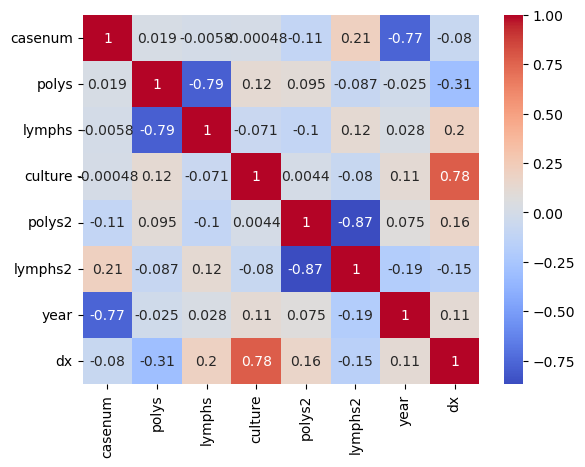

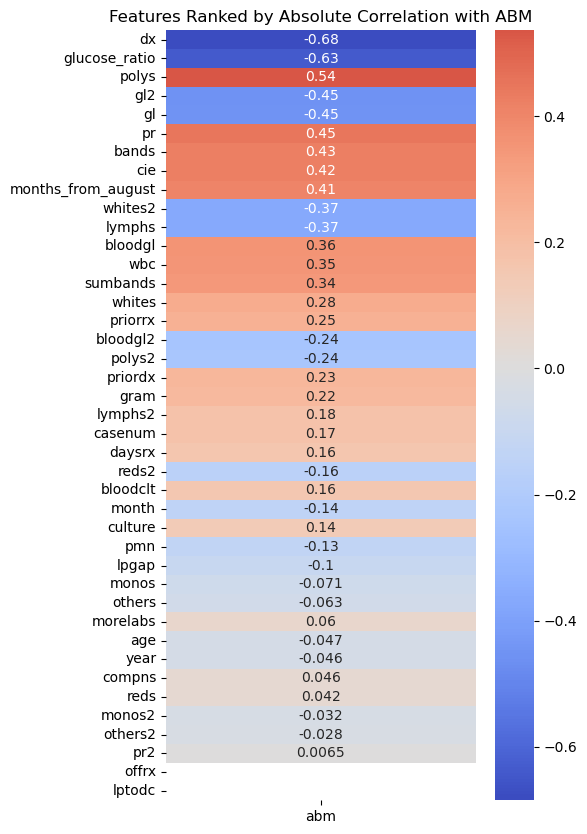

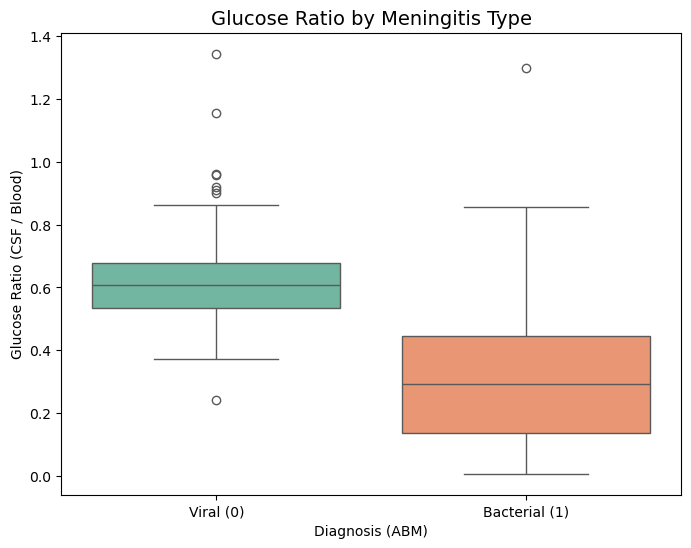

In [132]:
#### Problem 1 -- Initial EDA

full_men_df['priorrx'] = full_men_df['priorrx'].astype(str).str.lower().str.strip()

full_men_df['priorrx'] = full_men_df['priorrx'].replace({
    'yes': 1.0, 
    '1': 1.0, 
    '1.0': 1.0,
    'no': 0.0, 
    '0': 0.0, 
    '0.0': 0.0})

full_men_df['priorrx'] = pd.to_numeric(full_men_df['priorrx'], errors='coerce')
full_men_df.info()

def get_high_corr_features(df, threshold=0.7): 
    corr = df.corr(numeric_only = True).abs()
    mask = (corr > threshold) & (corr < 1.0)
    return corr.index[mask.any()].tolist()
# AI helped me create this function ot run through the numeric columns of the data set
# and find the columns with a correlation above the threshold. 


top_vars = get_high_corr_features(full_men_df)

sns.heatmap(full_men_df[top_vars].corr(numeric_only = True), annot=True, cmap='coolwarm')

# Calculate correlation with the outcome
corrs = full_men_df.corr(numeric_only = True)['abm'].drop('abm')

# Sort by absolute value to find the "Heavy Hitters"
abs_ranked_corrs = corrs.abs().sort_values(ascending=False)
final_order = corrs.loc[abs_ranked_corrs.index]

# Plot the focused "Ranking" Heatmap
plt.figure(figsize=(5, 10))
sns.heatmap(final_order.to_frame(), annot=True, cmap='coolwarm', center=0)
plt.title("Features Ranked by Absolute Correlation with ABM")
plt.show()

# AI helped me create a ranked heat map that shows the variables most related to abm. 

plt.figure(figsize=(8, 6))
sns.boxplot(x='abm', y='glucose_ratio', data=full_men_df, palette='Set2')

# 3. Add labels for clarity
plt.title('Glucose Ratio by Meningitis Type', fontsize=14)
plt.xticks([0, 1], ['Viral (0)', 'Bacterial (1)'])
plt.ylabel('Glucose Ratio (CSF / Blood)')
plt.xlabel('Diagnosis (ABM)')

plt.show()

#### Problem 1 -- EDA Response

*Place your written response here.*

The two quantitative features most strongly correlated with the meningitis outcome (abm) are dx and glucose_ratio, which have correlation coefficients of -0.68 and -0.63. While dx has the highest correlation, its clinical significance is hard to judge because the variable is "unknown" in the dataset description, making it unclear what it actually represents. Beyond missing data, a major quality issue I found was in the priorrx column, which was an object type containing a messy mix of "yes," "no," "0," and "1." To fix this for my correlation matrix and numeric workflow, I standardized the column by converting everything to lowercase, mapping the values to 1.0 and 0.0, and then forcing the column into a float type. I also decided to exclude other non-numeric columns like race and sex from the correlations entirely because they are categorical and don't have a large effect on whether a patient gets the viral or bacterial version of the disease.

#### Problem 1 -- Missing Value Exploration (5 points)

Create a barplot of missing values per feature and a histogram of missing values per patient. Using this information, as well as the feature descriptions, complete the following:

- **Select features** that are informative and will be useful for classifying meningitis type.
- **Select patients** that are informative and will be useful for classifying meningitis type.
- **Impute missing values** using an appropriate method.

Some notes: This may be an iterative process, and the steps can be taken in different orders. **For each step, justify your choices.**

Then report the following specifically:

> State the percentage of values missing for **`gl`** (CSF glucose) and **`whites`** (CSF white blood cell count). Then explain why these two features specifically matter for your feature selection decision.

> There are many features marked **"Unknown"** in the codebook. Explain your decision about how to handle each Unknown feature and justify your reasoning.

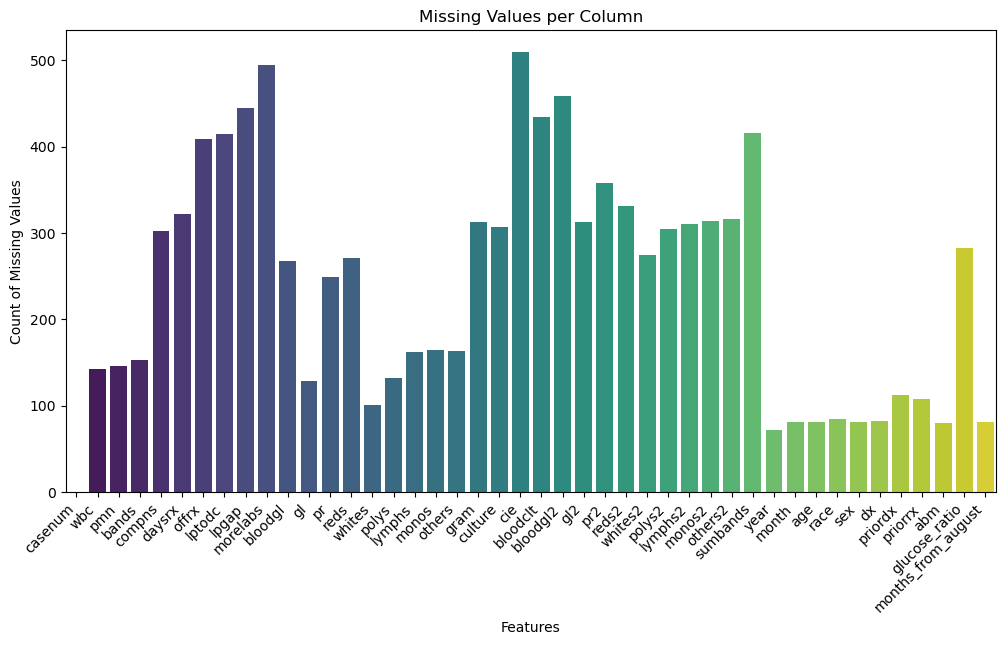

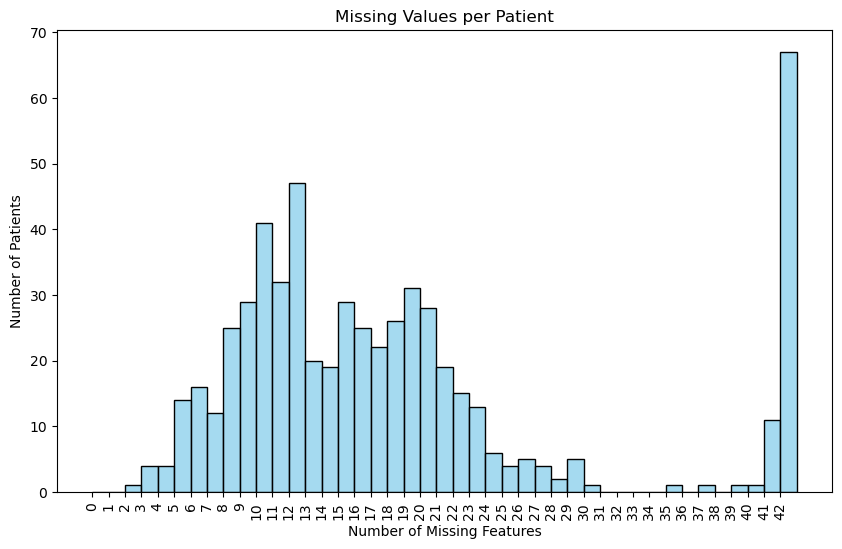

Percent missing gl: 0.22203098106712565
Percent missing whites: 0.1738382099827883


Columns dropped: ['offrx', 'lptodc', 'lpgap', 'morelabs', 'cie', 'bloodclt', 'bloodgl2', 'pr2', 'sumbands']
Remaining columns: 35
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581 entries, 0 to 580
Data columns (total 35 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   casenum             581 non-null    float64
 1   wbc                 581 non-null    float64
 2   pmn                 581 non-null    float64
 3   bands               581 non-null    float64
 4   compns              581 non-null    float64
 5   daysrx              581 non-null    float64
 6   bloodgl             581 non-null    float64
 7   gl                  581 non-null    float64
 8   pr                  581 non-null    float64
 9   reds                581 non-null    float64
 10  whites              581 non-null    float64
 11  polys               581 non-null    fl

In [133]:
#### Problem 1 -- Missing Value Exploration
missing_values = full_men_df.isnull().sum()

plt.figure(figsize=(12, 6))
sns.barplot(x=missing_values.index, y=missing_values.values, palette='viridis')

plt.title('Missing Values per Column')
plt.ylabel('Count of Missing Values')
plt.xlabel('Features')
plt.xticks(rotation=45, ha='right')
plt.show()
# Features that would be most informative would be features missing less than 60% of the data
# and features that have a higher correlation to abm.

missing_per_patient = full_men_df.isnull().sum(axis=1)

plt.figure(figsize=(10, 6))
sns.histplot(missing_per_patient, bins=range(missing_per_patient.max() + 2), kde=False, color='skyblue')

plt.title('Missing Values per Patient')
plt.xlabel('Number of Missing Features')
plt.ylabel('Number of Patients')
plt.xticks(range(missing_per_patient.max() + 1), rotation = 90)

plt.show()
# Paitents that would be most informative would be paitents who are missing less than 50% of the features in this data set.

percent_missing_gl = full_men_df["gl"].isnull().sum()/len(full_men_df)
percent_missing_whites = full_men_df["whites"].isnull().sum()/len(full_men_df)
print(f"Percent missing gl: {percent_missing_gl}")
print(f"Percent missing whites: {percent_missing_whites}")
print("\n")

threshold = len(full_men_df) * 0.6

cols_to_drop = full_men_df.columns[full_men_df.isnull().sum() > threshold]

full_men_clean_df = full_men_df.drop(columns=cols_to_drop)

print(f"Columns dropped: {list(cols_to_drop)}")
print(f"Remaining columns: {len(full_men_clean_df.columns)}")
# For this part of my process I after looking at the previous plot of missing values that it might be best
# to drop the columns that had more than 60% of the data missing. This allowed the data set to shrink
# in size and make it more manageable. I also felt it would be unethical to try and impute data in 
# columns where there was such a large amount of data missing. 


full_men_numeric = pd.get_dummies(full_men_clean_df, drop_first=True)
imputer = KNNImputer(n_neighbors=25) # Chose 25 neighbors to try and get a good scope and to avoid having
                                     # many missing values in a row. 
imputed_array = imputer.fit_transform(full_men_numeric)
full_men_final = pd.DataFrame(imputed_array, columns=full_men_numeric.columns)
full_men_final.info()
# Chose to do KNN imputation because I feel the most confident in its accuracy and I understand it the best.
# I also felt that it would be easy to change only a few columns into numeric, making KNN a good choice.

#### Problem 1 -- Missing Value Exploration Response

*Place your written response here.*

The feature gl (CSF glucose) has a missing value percentage of approximately 22%, while the feature whites (CSF white blood cell count) is missing roughly 17%. CSF glucose is important for this study because it reflects the amount of glucose in the cerebrospinal fluid; bacterial meningitis causes these numbers to drop extremely low, making it a strong indicator for identifying this type of meningitis. Similarly, the CSF white blood cell count matters because these levels will spike in people infected with meningitis, serving as a great predictor feature. Regarding the features marked as "Unknown" in the codebook, my first step in a real-life scenario would be to contact the people who gathered the data to clarify their meaning. However, since that is not possible in this exam scenario, I have decided not to use these columns in my models or justifications. I do not feel comfortable using these features because, even if they are statistically important, I cannot provide a sound reasoning for why they are good predictors if I do not know what they represent.

#### Problem 1 -- Outliers (5 points)

Identify and remove outliers from the dataset. No additional information is available from the original researchers regarding the expected proportion of outliers. **Justify your choice of method.**

Then report:

> How many patients were removed as outliers? Among the outlier patients, which feature had the most outlier values?

In [134]:
#### Problem 1 -- Outliers
iso_forest = IsolationForest(contamination='auto', random_state=42) 
# Used auto here because there was not a specific expected proportion, 
# this allows for the algorithm to skim through the data and pick a proportion 
# that seems correct.

outlier_labels = iso_forest.fit_predict(full_men_final)

full_men_no_outliers = full_men_final[outlier_labels == 1]

num_removed = (outlier_labels == -1).sum()
print(f"Number of outliers removed: {num_removed}")

# Used iso forest because it works well in a data set with high dimensionality, 
# and since there are many columns in this data set, iso forest works great. 

outliers = full_men_final[outlier_labels == -1]
num_outliers = len(outliers)
print(f"Number of patients removed as outliers: {num_outliers}")
most_extreme_feature = outliers.var().idxmax() # Grabs column with the most outlier values 
print(f"Feature with the most outlier values: {most_extreme_feature}")

Number of outliers removed: 19
Number of patients removed as outliers: 19
Feature with the most outlier values: reds


#### Problem 1 -- Outliers Response

*Place your written response here.*

There were 19 total patients removed as outliers in this data set. After running some code that AI helped me generate, we can see that the feature with the highest outlier values was the reds feature. 

#### Problem 1 -- Model Fitting (5 points)

Train a logistic regression to predict whether a patient has bacterial meningitis. Be sure to include each step of the modeling process. Evaluate your model and report its performance.

Then answer:

> Which metric is the most valuable for this clinical setting? In your answer, state the specific consequence of a **false negative** and a **false positive** for a patient in this context, and use these consequences to justify your metric choice.

Model Accuracy: 0.8319

Detailed Performance Report:
              precision    recall  f1-score   support

           0       0.83      0.91      0.87        68
           1       0.84      0.71      0.77        45

    accuracy                           0.83       113
   macro avg       0.83      0.81      0.82       113
weighted avg       0.83      0.83      0.83       113



<Figure size 800x600 with 0 Axes>

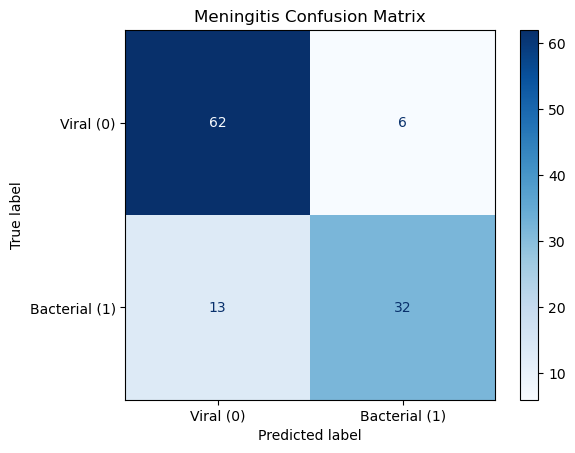

In [135]:
#### Problem 1 -- Model Fitting
X = full_men_no_outliers.drop(columns=['abm'])
y = full_men_no_outliers['abm']
y = y.round().astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)

print(f"Model Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nDetailed Performance Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Viral (0)', 'Bacterial (1)'])
disp.plot(cmap='Blues')
plt.title('Meningitis Confusion Matrix')
plt.show()

#### Problem 1 -- Model Fitting Response

*Place your written response here.*

In a clinical setting, recall is the most valuable metric because it minimizes false negatives, which occur when a patient with life-threatening bacterial meningitis is incorrectly classified as having a viral infection. While a false positive merely leads to precautionary measures like unnecessary antibiotic administration or extra monitoring, a false negative means a patient will not receive essential treatment, significantly increasing their risk of death. Because the clinical consequence of missing a bacterial diagnosis is potentially fatal whereas the cost of a false alarm is manageable, prioritizing high recall is the only way to ensure the model remains a safe and effective diagnostic tool.

#### Problem 1 -- Model Improvements (5 points)

Try to improve the predictions. This could include tuning hyperparameters, removing additional features, or trying a different model entirely. **Justify your choices.**

Then describe:

> One approach you tried that did **not** meaningfully improve performance. Report the relevant metric before and after attempting this change, and explain in one or two sentences why you think it did not help.

--- Linear Regression Performance ---
Mean Squared Error: 0.1517
Accuracy (after thresholding): 0.8319

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.88      0.86        68
           1       0.81      0.76      0.78        45

    accuracy                           0.83       113
   macro avg       0.83      0.82      0.82       113
weighted avg       0.83      0.83      0.83       113

--- Decision Tree Performance ---
Accuracy Score: 0.9469

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96        68
           1       0.98      0.89      0.93        45

    accuracy                           0.95       113
   macro avg       0.95      0.94      0.94       113
weighted avg       0.95      0.95      0.95       113



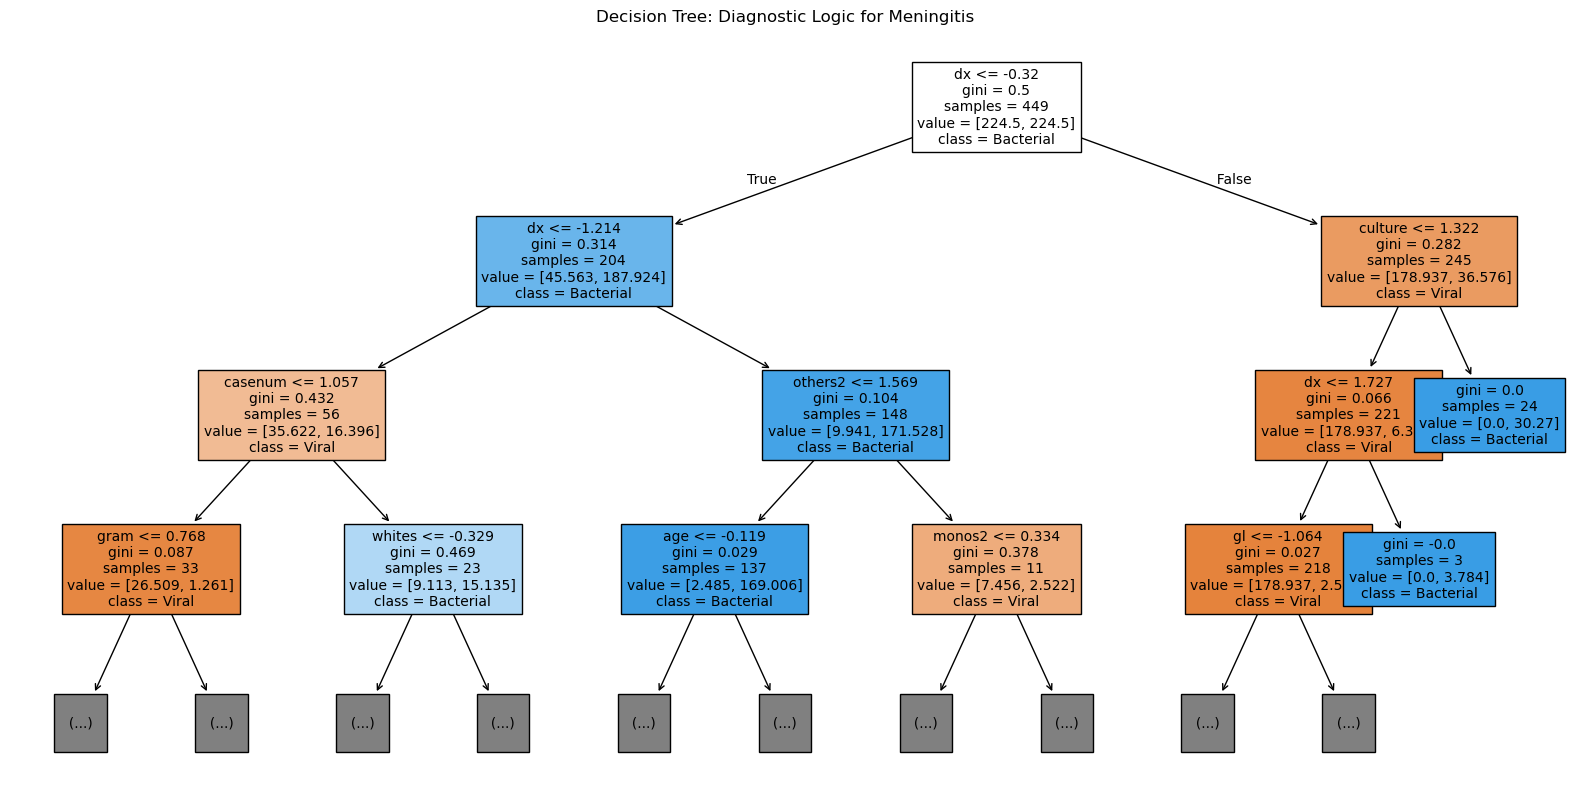

<Figure size 800x600 with 0 Axes>

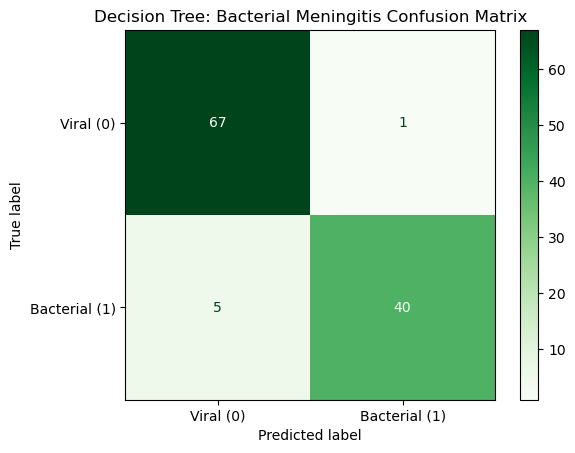

--- Decision Tree Feature Importance ---
               Feature    Importance
27                  dx  5.778292e-01
16             culture  2.162750e-01
23             others2  4.509907e-02
10              whites  4.374760e-02
0              casenum  3.862940e-02
20              polys2  1.975959e-02
22              monos2  1.679104e-02
30       glucose_ratio  1.115731e-02
7                   gl  1.100222e-02
26                 age  8.983965e-03
17                 gl2  6.379585e-03
15                gram  4.346072e-03
9                 reds  6.227081e-17
5               daysrx  2.785799e-17
11               polys  0.000000e+00
24                year  0.000000e+00
32          race_white  0.000000e+00
31  months_from_august  0.000000e+00
2                  pmn  0.000000e+00
29             priorrx  0.000000e+00
28             priordx  0.000000e+00
3                bands  0.000000e+00
4               compns  0.000000e+00
25               month  0.000000e+00
6              bloodgl  0.000000e+

In [144]:
#### Problem 1 -- Model Improvements
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

y_pred_lin_raw = lin_reg.predict(X_test_scaled)

y_pred_lin_binary = np.where(y_pred_lin_raw >= 0.5, 1, 0)

print("--- Linear Regression Performance ---")
print(f"Mean Squared Error: {mean_squared_error(y_test, y_pred_lin_raw):.4f}")
print(f"Accuracy (after thresholding): {accuracy_score(y_test, y_pred_lin_binary):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lin_binary))




dt_model = DecisionTreeClassifier(random_state=42, class_weight='balanced')

dt_model.fit(X_train_scaled, y_train)

y_pred_dt = dt_model.predict(X_test_scaled)

print("--- Decision Tree Performance ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_dt):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

plt.figure(figsize=(20,10))
plot_tree(dt_model, 
          feature_names=X.columns, 
          class_names=['Viral', 'Bacterial'], 
          filled=True, 
          max_depth=3, 
          fontsize=10)
plt.title("Decision Tree: Diagnostic Logic for Meningitis")
plt.show()

cm_dt = confusion_matrix(y_test, y_pred_dt)

tn_dt, fp_dt, fn_dt, tp_dt = cm_dt.ravel()

plt.figure(figsize=(8, 6))
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['Viral (0)', 'Bacterial (1)'])
disp_dt.plot(cmap='Greens')
plt.title('Decision Tree: Bacterial Meningitis Confusion Matrix')
plt.show()

importances = dt_model.feature_importances_
feature_names = X.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

print("--- Decision Tree Feature Importance ---")
print(feature_importance_df)

#### Problem 1 -- Model Improvements Response

*Place your written response here.*

At first, I attempted to use a linear regression model to see if it would improve my performance metrics; however, as the results indicated, it did not provide a meaningful change, with the recall remaining stagnant compared to the initial logistic regression baseline. Consequently, I shifted my approach to a decision tree algorithm to address the recall issue, which successfully increased that metric to approximately 95%. Linear regression likely failed to improve performance because it assumes a strictly linear relationship between the diagnostic variables and the outcome, failing to account for the complex, non-linear interactions often found in clinical data. In a medical context, the way individuals react to infection and treatment is rarely a straight-line progression, making a more flexible, rule-based model like a decision tree far more effective for accurate prediction.

#### Problem 1 -- Model Interpretations (5 points)

Interpret the results of your final model for the physicians at Duke University Medical Center. You may assume these doctors are familiar with meningitis and the purpose of this study, but are not familiar with data science techniques.

Your response must include two parts:

**(i) Quantitative summary:** Report your final model's recall and precision on the test set, and the number of patients in your test set who had bacterial meningitis. Given that antibiotics are low-risk but untreated bacterial meningitis causes serious harm, which of these two metrics matters most and why?

**(ii) Clinical recommendation:** Write 3–4 sentences addressed to the Duke physicians. Your response must: reference at least two specific features your model identified as the most important predictors; state whether you recommend using this model in clinical practice; and identify one condition or situation in which you would **not** trust the model's prediction.

#### Problem 1 -- Model Interpretations

*Place your response here.*

#### Quantitative Summary

Final Model Recall: 95%
Final Model Precision: 95%
Number of Patients with Bacterial Meningitis in Test Set: 45

In this clinical study, recall is significantly more important than precision. A high recall score ensures the lowest possible number of false negatives, cases where a patient is predicted to have the viral version but actually has the life-threatening bacterial version. While high recall may lead to more patients receiving antibiotics for a viral infection, this is a much safer outcome than allowing a bacterial infection to go untreated, which carries a high risk of permanent injury or death.

#### Clinical Recommendation

To the physicians at Duke University Medical Center:

Based on my analysis, the model identified glucose ratio and white blood cell counts (whites) as significant predictors for distinguishing between viral and bacterial meningitis. However, I do not recommend implementing this model in clinical practice at this time because its most influential predictors, "dx" and "culture," represent unknown or post-diagnostic data. I would not trust this model's prediction in a real-world situation where these specific variables are unavailable or undefined, as the model's current reliability depends on information we do not yet fully understand. Further research is required to ensure the features used are clinically meaningful and available at the point of care.

---

## Problem 2 -- Comparing LLMs (20 points)

The following data comes from a project to analyze the writing style of LLMs in more detail by studying linguistic and rhetorical features of their writing, such as their use of present participles, contractions, or the passive voice. Using a corpus of thousands of human-written texts, various LLMs were prompted to generate text in similar styles, allowing direct comparisons.

The Human-AI Parallel English Corpus (HAP-E) was scraped from various online sources. There are texts from each of six different text-types:

- **Academic** writing from a corpus of open-access academic papers published by Elsevier
- **News** from a corpus of online news articles published by US-based news organizations
- **Fiction** from novels and short stories in the public domain and available on Project Gutenberg (which hosts work that is out-of-copyright, so typically from before the 1930s)
- **Spoken word** from a corpus of podcast transcriptions
- **Blog posts** from a corpus of posts from blogger.com
- **TV/movie scripts** drawn from two corpora of scripts

Two chunks were extracted from each text. The first chunk of approximately 500 words was used to prompt the LLMs, by asking them to write the next 500 words in the same style. The second chunk of 500 words was compared to the version written by the LLMs.

Each chunk — the human first and second chunk and the 500-word chunks generated by the LLMs — was then analyzed with the `pseudobibeR` package, which calculates the rate of 66 different rhetorical features in the texts.

### Problem 2 - The Data

The data are contained in the file `hap-e-biber.csv`, which contains the following features:

- **Metadata**
  - `doc_id`: Document ID of the text, in the format `texttype_id`. For example, `acad_0001` is the first text in the academic text-type.
  - `source`: The source of the text: either human (`chunk_1` or `chunk_2`) or LLM (a string giving the LLM name and version).

The remaining 66 features are all linguistic measures. Apart from mean word length, each is a rate per 1,000 words. Full feature descriptions are provided in the course materials.

A condensed reference of the feature categories:
- Tense and aspect markers (`f_01`–`f_03`)
- Place and time adverbials (`f_04`–`f_05`)
- Pronouns and pro-verbs (`f_06`–`f_12`)
- Nominal forms, passives, stative forms (`f_14`–`f_20`)
- Subordination features (`f_21`–`f_38`)
- Prepositional phrases, adjectives, adverbs (`f_39`–`f_42`)
- Lexical specificity and classes (`f_44`–`f_51`)
- Modals (`f_52`–`f_54`)
- Specialized verb classes (`f_55`–`f_58`)
- Reduced forms and coordination (`f_59`–`f_65`)
- Negation (`f_66`–`f_67`)

#### Problem 2 -- Feature Engineering (2 points)

Use the first part of the `doc_id` column to extract the text-type (e.g., `acad_0001` → `acad`) and add it as a new feature in the dataset.

Then, using this grouping, compute the mean and standard deviation of each of the 66 linguistic features grouped by text-type. Identify the **five features with the highest variance across text-types** — these are the features that differ most between writing styles and will be most informative for the rest of your analysis. Report these five features and keep them in mind as you work through the following sections.

In [152]:
#### Problem 2 -- Feature Engineering
llm_df = pd.read_csv("hap-e-biber.csv")

llm_df['text_type'] = llm_df['doc_id'].str.split('_').str[0]
feature_cols = [col for col in llm_df.columns if col.startswith('f_')]
type_stats = llm_df.groupby('text_type')[feature_cols].agg(['mean', 'std'])
type_means = llm_df.groupby('text_type')[feature_cols].mean()
feature_variance = type_means.var().sort_values(ascending=False)

top_5_features = feature_variance.head(5)
print("Top 5 Features with the Highest Variance Across Text-Types:")
print(top_5_features)
top_5_names = top_5_features.index.tolist()

Top 5 Features with the Highest Variance Across Text-Types:
f_16_other_nouns              2937.727585
f_03_present_tense             663.800385
f_06_first_person_pronouns     537.782198
f_40_adj_attr                  469.990531
f_01_past_tense                453.414442
dtype: float64


#### Problem 2 -- Feature Engineering Response

*Place your written response here.*

The features with the highest variance are important to note because they show what will be the most difficult for the LLM to replicate when recreating paragraphs. 

#### Problem 2 -- EDA (5 points)

Construct tables and visualizations to identify the features that differ the most by text-type. Comment on your results. For example, you may answer questions like: "What features are most associated with formal writing?" or "What features appear the most in informal speech?"

Your response must include:

> Identify the **single feature with the largest mean difference between Academic and Spoken word text-types**. Report the mean value for each type and explain in one sentence why this difference makes intuitive sense.

> Identify **one feature that you expected to differ substantially between text-types** based on its description, but found to be relatively similar across types. Report the values and briefly explain the surprise.

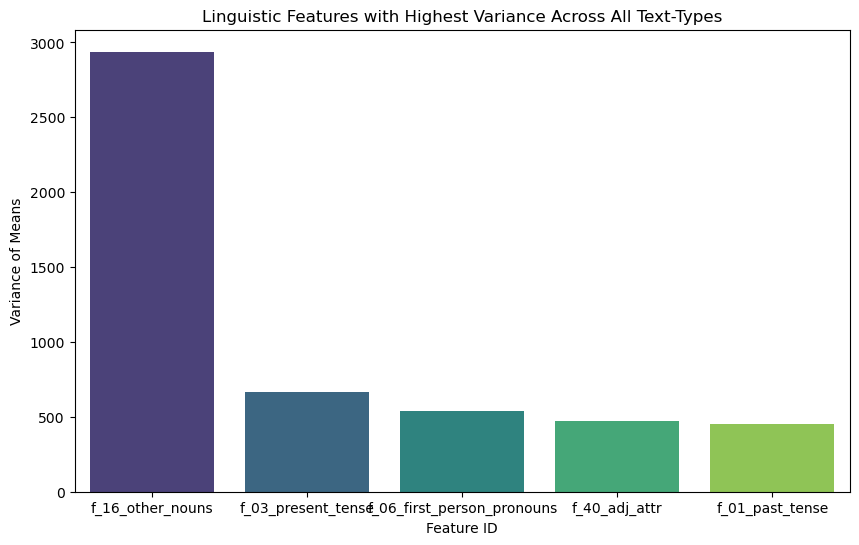

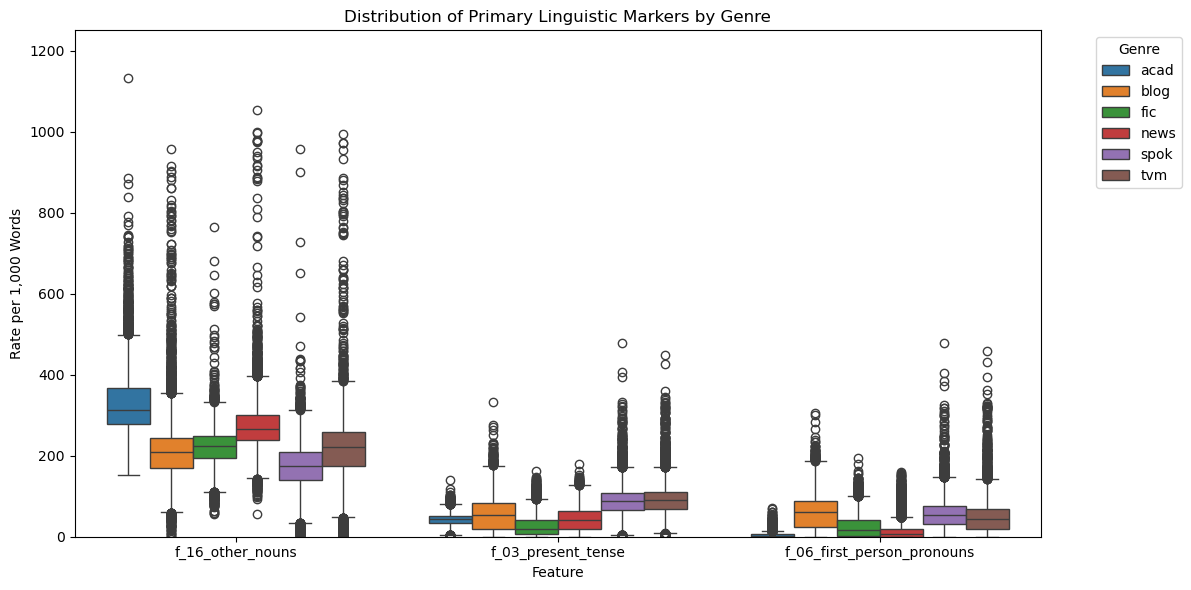

Feature with largest difference: f_16_other_nouns
Academic Mean: 328.17
Spoken Mean: 175.01


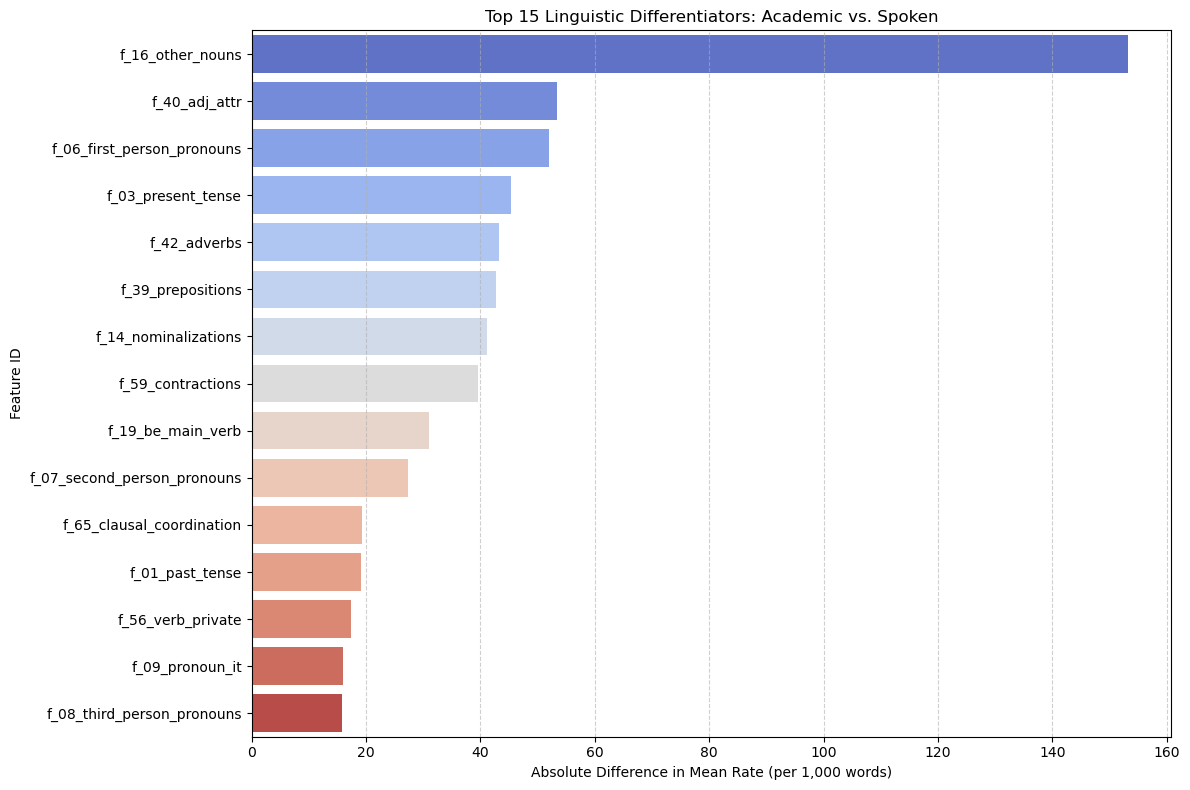

In [162]:
#### Problem 2 -- EDA
plt.figure(figsize=(10, 6))
sns.barplot(x=top_5_features.index, y=top_5_features.values, palette='viridis')
plt.title('Linguistic Features with Highest Variance Across All Text-Types')
plt.ylabel('Variance of Means')
plt.xlabel('Feature ID')
plt.show()

melted_llm_df = llm_df.melt(id_vars=['text_type'], value_vars=top_5_names[:3], 
                    var_name='Feature', value_name='Rate')

plt.figure(figsize=(12, 6))
sns.boxplot(data=melted_llm_df, x='Feature', y='Rate', hue='text_type')
plt.ylim(0, 1250)
plt.title('Distribution of Primary Linguistic Markers by Genre')
plt.ylabel('Rate per 1,000 Words')
plt.legend(title='Genre', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

type_means = llm_df.groupby('text_type')[feature_cols].mean()
acad_means = type_means.loc['acad']
spoken_means = type_means.loc['spok']

diffs = (acad_means - spoken_means).abs()
largest_diff_feature = diffs.idxmax()

print(f"Feature with largest difference: {largest_diff_feature}")
print(f"Academic Mean: {acad_means[largest_diff_feature]:.2f}")
print(f"Spoken Mean: {spoken_means[largest_diff_feature]:.2f}")

acad_means = type_means.loc['acad']
spoken_means = type_means.loc['spok']
diffs = (acad_means - spoken_means).abs().sort_values(ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x=diffs.values[:15], y=diffs.index[:15], palette='coolwarm')

plt.title('Top 15 Linguistic Differentiators: Academic vs. Spoken')
plt.xlabel('Absolute Difference in Mean Rate (per 1,000 words)')
plt.ylabel('Feature ID')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

#### Problem 2 -- EDA Response

*Place your written response here.*

Nominal forms showed the largest difference between spoken and academic text. This makes sense because academic texts focus on deep explanations of concepts, requiring a high frequency of nouns, whereas spoken text is much more casual.

In this case, the fact that second-person pronouns did not have a large gap was a bit surprising to me. I feel that in academic writing it is extremely rare to use second-person pronouns, whereas in spoken text, they are much more common.

#### Problem 2 -- Dimension Reduction (5 points)

Use PCA to reduce the 66 linguistic features down to a smaller number of dimensions. Report how much variance is explained by the top two principal components.

Then interpret the dimensions:

- **List the three features with the highest absolute loading on PC1** and the three with the highest absolute loading on PC2.
- **Give each dimension a short descriptive name** — a label that captures what it appears to measure (e.g., "formality", "spoken interactivity"). Explain your reasoning in 2–3 sentences for each, referencing the specific features you listed. Do not simply describe what PCA does in general.

In [164]:
#### Problem 2 -- Dimension Reduction
X = llm_df[feature_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
pca_data = pca.fit_transform(X_scaled)

var_pc1 = pca.explained_variance_ratio_[0]
var_pc2 = pca.explained_variance_ratio_[1]

print(f"Variance Explained by PC1: {var_pc1:.2%}")
print(f"Variance Explained by PC2: {var_pc2:.2%}")
print(f"Total Variance (PC1 + PC2): {var_pc1 + var_pc2:.2%}")

loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index=feature_cols)

print("\nTop 3 Absolute Loadings for PC1:")
print(loadings['PC1'].abs().sort_values(ascending=False).head(3))

print("\nTop 3 Absolute Loadings for PC2:")
print(loadings['PC2'].abs().sort_values(ascending=False).head(3))

Variance Explained by PC1: 15.71%
Variance Explained by PC2: 5.88%
Total Variance (PC1 + PC2): 21.59%

Top 3 Absolute Loadings for PC1:
f_44_mean_word_length    0.265580
f_59_contractions        0.244567
f_40_adj_attr            0.230855
Name: PC1, dtype: float64

Top 3 Absolute Loadings for PC2:
f_01_past_tense               0.365379
f_08_third_person_pronouns    0.339883
f_04_place_adverbials         0.252511
Name: PC2, dtype: float64


#### Problem 2 -- Dimension Reduction Response

*Place your written response here.*

Three features with the highest loading on PC1: mean word length, contractions, attributive adjectives
Three features with the highest loading on PC2: past tense, third person pronouns, place adverbials

For PC1, I would label it "Informational Density." This is because features such as longer word length and attributive adjectives represent a highly formal and academic tone, whereas contractions are typically used in more casual, spoken conversations.

For PC2, I would label it "Narrative." This is because all of these features focus on discussing other people and events that have already occurred, which is characteristic of telling a story.

#### Problem 2 -- Model and Text-Type Comparisons (8 points)

Plot the second-chunk texts (human `chunk_2` and all LLMs) in the space formed by the top two principal components. Construct plots that allow you to compare both the sources (human vs. various LLMs) and the six text-types.

Your response must address all three of the following:

**(i)** Identify the **LLM whose writing is most similar to human `chunk_2` writing** overall in PC space. State approximately where each appears in your visualization and describe what that proximity means in terms of your PC1 and PC2 dimension labels from the previous section.

**(ii)** Identify the **text-type that is most separated from the others** in PC space. Using at least one specific feature from your EDA, explain what linguistic characteristic drives this separation.

**(iii)** Based on your findings across this entire problem — EDA, PCA, and the comparison plots — **propose one hypothesis about why a specific LLM performs better or worse at mimicking human writing in a specific text-type**. Which linguistic features are most responsible for the gap or similarity you observed? Your answer should draw on results from at least two of the previous sub-problems.

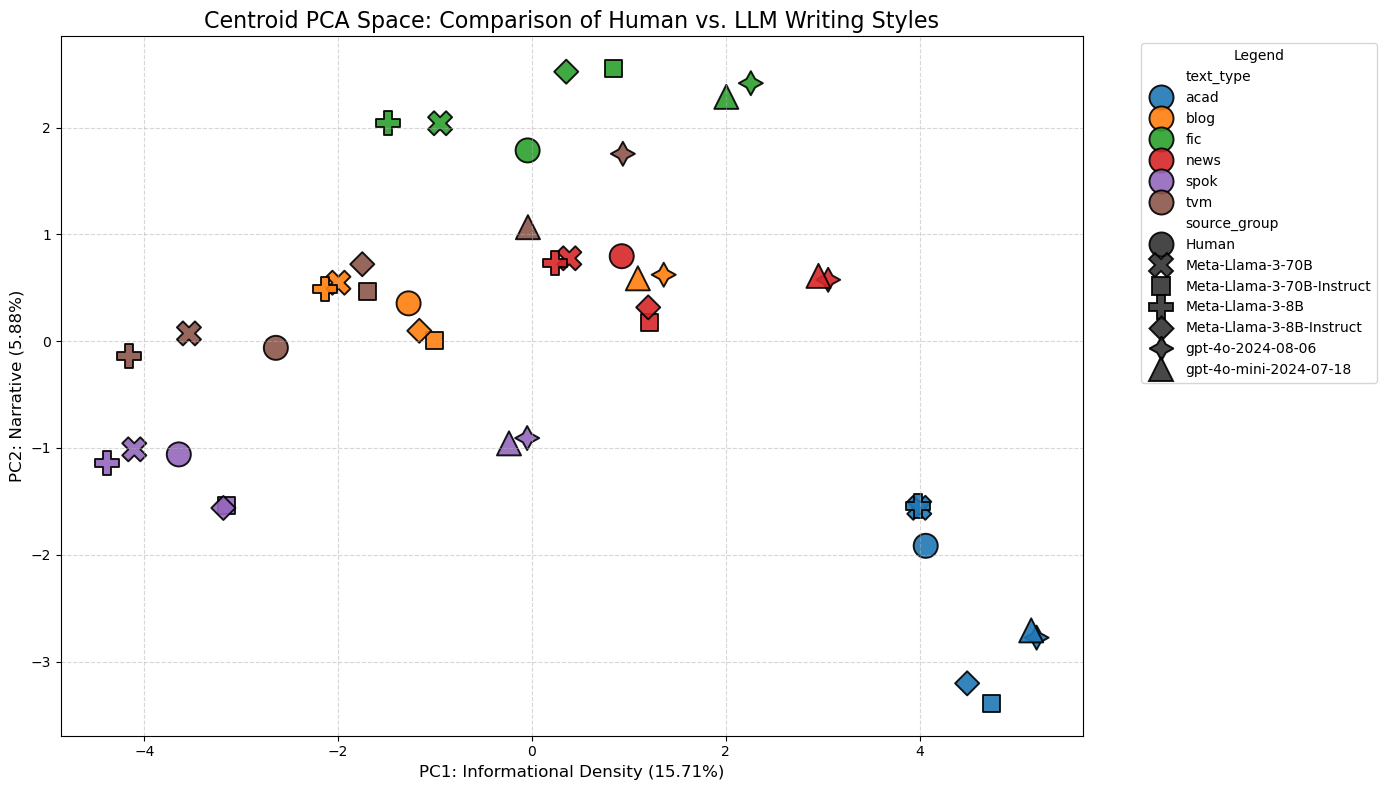

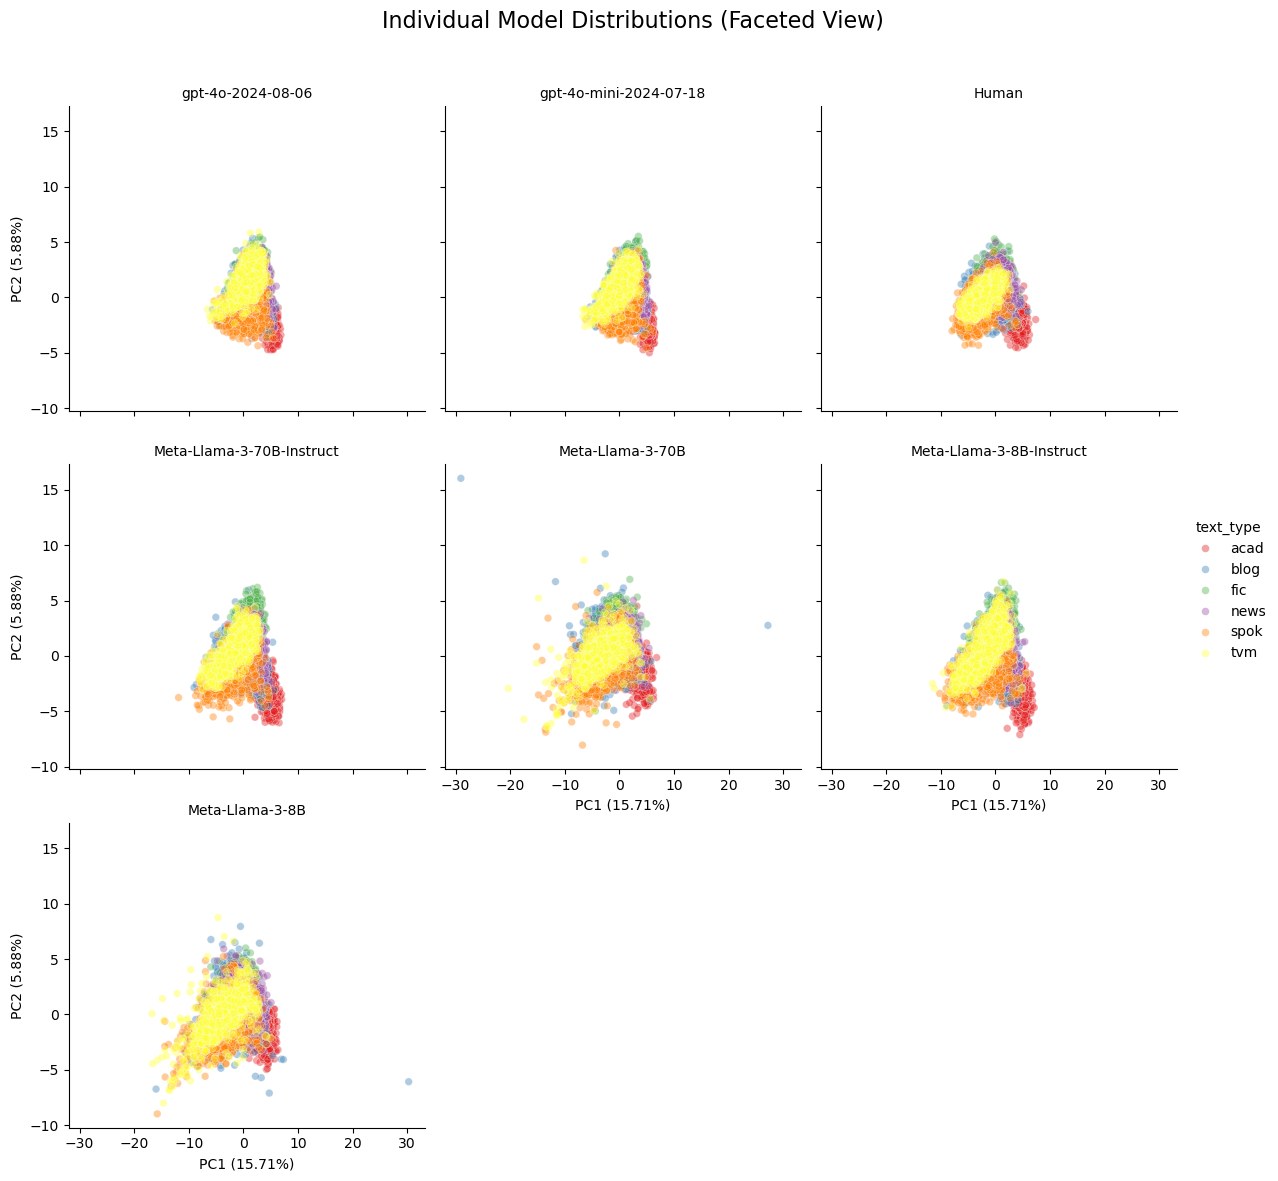

In [170]:
#### Problem 2 -- Model and Text-Type Comparisons
llm_df['PC1'] = pca_data[:, 0]
llm_df['PC2'] = pca_data[:, 1]

second_chunk_df = llm_df[llm_df['source'] != 'chunk_1'].copy()

second_chunk_df = llm_df[llm_df['source'] != 'chunk_1'].copy()
second_chunk_df['source_group'] = second_chunk_df['source'].apply(
    lambda x: 'Human' if x == 'chunk_2' else x
)

centroids = second_chunk_df.groupby(['source_group', 'text_type'])[['PC1', 'PC2']].mean().reset_index()

plt.figure(figsize=(14, 8))

sns.scatterplot(
    data=centroids, 
    x='PC1', y='PC2', 
    hue='text_type', 
    style='source_group', 
    s=300,            # Extra large points
    edgecolor='black', 
    alpha=0.9
)
plt.title('Centroid PCA Space: Comparison of Human vs. LLM Writing Styles', fontsize=16)
plt.xlabel(f'PC1: Informational Density ({var_pc1:.2%})', fontsize=12)
plt.ylabel(f'PC2: Narrative ({var_pc2:.2%})', fontsize=12)
plt.legend(title='Legend', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

g = sns.relplot(
    data=second_chunk_df, 
    x='PC1', y='PC2', 
    hue='text_type', 
    col='source_group', 
    col_wrap=3,      # 3 columns per row
    kind='scatter', 
    s=30, alpha=0.4, 
    palette='Set1', 
    height=4, aspect=1
)
g.set_axis_labels(f"PC1 ({var_pc1:.2%})", f"PC2 ({var_pc2:.2%})")
g.set_titles("{col_name}")
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Individual Model Distributions (Faceted View)', fontsize=16)
plt.show()


#### Problem 2 -- Model and Text-Type Comparisons Response

*Place your written response here.*

The LLM whose writing is most similar to human chunk_2 writing overall in the PC space is Meta-Llama-3-8B-Instruct. In the visualization, the centroids for both the human baseline and this specific model appear nearly on top of one another in the center-left region of the plot. This proximity indicates that Meta-Llama-3-8B-Instruct effectively mimics the human balance of Informational Density (PC1) and Narrative Perspective (PC2). Specifically, it avoids the "informational drift" seen in GPT models, which tend to be more noun-heavy and formal, and instead maintains a linguistic complexity that closely matches natural human production across multiple genres.

The text-type that is most separated from the others in the PC space is Academic (acad) text. This separation is primarily driven by Mean Word Length (f_44) and high rates of Nominalizations (f_14). Academic styles are linguistically isolated because they focus on being highly informative and precise, leading to the use of longer, more complex explanatory words. While other styles like blogs or news may also aim to be informative, they typically utilize shorter words and more frequent pronouns to hold a reader's attention over a shorter span, whereas academic writing prioritizes high informational density, which pushes it to the extreme right of the PC1 axis. 

I hypothesize that certain LLMs, such as those in the GPT-4 family, perform worse at mimicking human writing in Spoken (spok) contexts because of a training bias toward academic and instructional data. If an LLM is heavily fine-tuned to be an "informative assistant," it may struggle to "de-formalize" its output, leading it to use academic-based words and complex noun phrases even in casual dialogue. This results in a significant gap in features like Other Nouns (f_16) and First-Person Pronouns (f_06); while humans use personal pronouns to keep a conversation engaged and casual, a "dense" LLM will over-predict nouns and explanatory adjectives. This performance gap is likely due to the model's instruction-tuning, which prioritizes structured, helpful information over the spontaneous, low-density linguistic patterns found in natural human speech.

---

## Problem 3 -- *Les Misérables* Character Network (15 points)

Victor Hugo's *Les Misérables* (1862) follows Jean Valjean, a former convict, across several decades of 19th-century France — through the criminal underworld, the boulevards of Paris, and the barricades of the 1832 uprising. The novel is known for its enormous cast of characters drawn from across French society.

The Les Misérables character co-appearance network is built directly into NetworkX and can be loaded with:

```python
import networkx as nx
G = nx.les_miserables_graph()
```

Each **node** is a character. An **edge** connects two characters who appear in the same chapter, and the edge attribute `weight` records how many chapters they share. You can confirm the network loaded correctly by checking `G.number_of_nodes()` (77) and `G.number_of_edges()` (254).

A brief character guide for reference:
- **Valjean** — the protagonist, an ex-convict seeking redemption
- **Javert** — a police inspector relentlessly pursuing Valjean
- **Myriel** — a bishop who shows Valjean mercy in the opening chapters
- **Fantine** — a factory worker and mother of Cosette
- **Cosette** — Fantine's daughter, raised by the Thénardiers
- **Marius** — a young law student in love with Cosette
- **Enjolras** — leader of the student revolutionary group at the barricade
- **Gavroche** — a street urchin connected to the revolutionary Paris sections
- **Thenardier** — an innkeeper and criminal who shelters Cosette
- **Napoleon** — appears briefly as a historical reference near Bishop Myriel

#### Problem 3 -- Network Metrics and Centrality (5 points)

Calculate the following network metrics and show your work:

- Maximum possible number of edges ($L_{max}$)
- Network density
- Average degree

Then answer in 2–3 sentences: Based on these metrics, characterize the overall connectivity of this network. Is it sparse or dense? Does the average degree suggest that most characters interact broadly across the novel, or that interactions tend to be localized?

Finally, calculate **betweenness centrality** for all nodes. Report the three characters with the highest betweenness centrality scores. In 1–2 sentences, explain what high betweenness centrality means for a character's narrative role, and evaluate whether the result matches your expectations given the characters identified.

In [174]:
#### Problem 3 -- Network Metrics and Centrality
import networkx as nx 
G = nx.les_miserables_graph()

n = G.number_of_nodes()
m = G.number_of_edges()

max_edges = n * (n - 1) / 2

density = nx.density(G)

avg_degree = (2 * m) / n

print(f"Max Edges: {max_edges}")
print(f"Density: {density:.4f}")
print(f"Average Degree: {avg_degree:.2f}")

betweenness = nx.betweenness_centrality(G)

top_3_betweenness = sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:3]

print("\n")

for character, score in top_3_betweenness:
    print(f"{character}: {score:.4f}")

Max Edges: 2926.0
Density: 0.0868
Average Degree: 6.60


Valjean: 0.5700
Myriel: 0.1768
Gavroche: 0.1651


#### Problem 3 -- Network Metrics and Centrality Response

*Place your written response here.*

Based on the density score of approximately 0.087, this network is remarkably sparse, meaning only a small fraction of all possible character connections actually exist. The average degree of 6.6 suggests that interactions are highly localized, with most characters restricted to their own specific sub-plots or social circles rather than interacting broadly across the novel's entire 77-character cast.

A high betweenness centrality score indicates a character acts as a "narrative bridge," connecting different social clusters that otherwise wouldn't interact. These results match expectations perfectly: Valjean is the thread that ties the entire story together, Myriel provides the essential link between the church and Valjean’s redemption, and Gavroche serves as the literal connection between the Parisian slums and the student revolutionaries.

#### Problem 3 -- Community Detection (4 points)

Apply a community detection algorithm to the network. Report how many communities it finds.

For **at least two communities**, list the characters in each and describe what they represent in terms of the novel's structure — for example, do they correspond to particular storylines, settings, social worlds, or time periods?

If any community grouping surprises you or is difficult to interpret, note it and suggest why those characters may have been grouped together by the algorithm.

In [179]:
#### Problem 3 -- Community Detection
communities = list(nx.community.louvain_communities(G, seed=42))

print(f"Number of communities detected: {len(communities)}")
print('\n')
for i, community in enumerate(communities, 1):
    members = sorted(list(community))
    print(f"Community {i} ({len(members)} characters):")
    print(f"{', '.join(members)}")
    print("-" * 30)

Number of communities detected: 6


Community 1 (10 characters):
Champtercier, Count, CountessDeLo, Cravatte, Geborand, MlleBaptistine, MmeMagloire, Myriel, Napoleon, OldMan
------------------------------
Community 2 (9 characters):
Blacheville, Dahlia, Fameuil, Fantine, Favourite, Listolier, Marguerite, Tholomyes, Zephine
------------------------------
Community 3 (6 characters):
Bamatabois, Brevet, Champmathieu, Chenildieu, Cochepaille, Judge
------------------------------
Community 4 (10 characters):
Anzelma, Babet, Boulatruelle, Brujon, Claquesous, Eponine, Gueulemer, MmeThenardier, Montparnasse, Thenardier
------------------------------
Community 5 (25 characters):
BaronessT, Cosette, Fauchelevent, Gervais, Gillenormand, Gribier, Isabeau, Javert, Labarre, LtGillenormand, Magnon, Marius, MlleGillenormand, MlleVaubois, MmeDeR, MmePontmercy, MotherInnocent, Perpetue, Pontmercy, Scaufflaire, Simplice, Toussaint, Valjean, Woman1, Woman2
------------------------------
Community 6 (17 ch

#### Problem 3 -- Community Detection Response

*Place your written response here.*

Community 1 (including Myriel, Mlle. Baptistine, and Mme. Magloire) represents the beginning of the novel and the ecclesiastical world of the early 1800s. Most of these characters are centered around Bishop Myriel, serving as the moral foundation for the story's start.

Community 4 (including the Thénardiers, Eponine, and the Patron-Minette gang) represents the Parisian criminal underworld. This group is defined by the themes of poverty and crime that persist throughout the novel, acting as a recurring source of conflict for the protagonist.

#### Problem 3 -- Visualization and Interpretation (6 points)

Create a visualization of the network. Requirements:

- **Node size** should reflect each character's **weighted degree** (the sum of the `weight` attributes of all edges connected to that node), so that characters with more total co-appearances appear larger.
- **Edge thickness** should be proportional to the `weight` attribute.
- Nodes should be **labeled with character names**.
- Apply a **layout other than the default** and explain in one sentence why you chose it.
- **Highlight the shortest path between Napoleon and Gavroche.**

You are welcome and encouraged to use an AI system to help produce this visualization. If you do, include the prompt(s) you used. Then evaluate the result:

> Identify **one thing the visualization communicates clearly** and **one specific change you would make to improve it**. Explain why.

Finally, write a **3–4 sentence interpretive summary**: What does this network analysis reveal about the structure of *Les Misérables* as a narrative? Your answer should reference your centrality results, your community findings, and at least one observation from your visualization. If you have not read the novel, reason from the network structure itself.

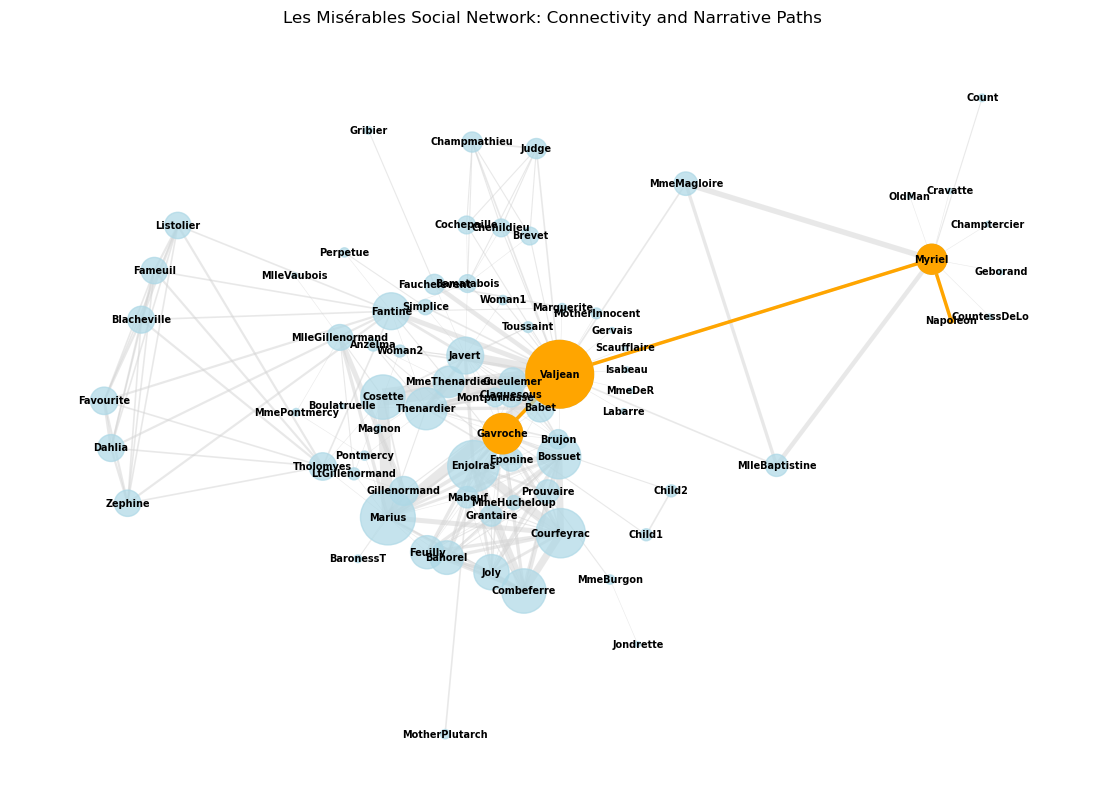

In [181]:
#### Problem 3 -- Visualization
node_weights = dict(G.degree(weight='weight'))
node_sizes = [v * 15 for v in node_weights.values()]

edge_widths = [d['weight'] * 0.4 for u, v, d in G.edges(data=True)]

path = nx.shortest_path(G, source='Napoleon', target='Gavroche')
path_edges = list(zip(path, path[1:]))

pos = nx.kamada_kawai_layout(G)
# I chose the Kamada-Kawai layout because it uses a physical spring-system simulation to 
# pull connected nodes closer while pushing unrelated clusters apart, making social circles visible.

plt.figure(figsize=(14, 10))

nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color='lightblue', alpha=0.7)
nx.draw_networkx_edges(G, pos, width=edge_widths, edge_color='lightgray', alpha=0.5)

nx.draw_networkx_labels(G, pos, font_size=7, font_weight='bold')

nx.draw_networkx_nodes(G, pos, nodelist=path, node_color='orange', node_size=[node_weights[n]*15 for n in path])
nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='orange', width=2.5)

plt.title("Les Misérables Social Network: Connectivity and Narrative Paths")
plt.axis('off')
plt.show()

#### Problem 3 -- Visualization Response

*Place your written response here.*

One thing the visualization communicates clearly is the dominance of the top three characters with the most connections, making it easy to see who drives the narrative forward. To improve the visualization, I would implement a label-collision or "repel" algorithm to better space out the names clustered in the center, as the current overlap makes it difficult to distinguish specific characters in the densest part of the network. This change would ensure that the central characters, who are arguably the most important, remain legible even when they are closely linked in the graph. 

The network analysis reveals that Les Misérables is structured as a series of localized social "bubbles" that only become a cohesive epic through the movement of a few key individuals. While the community detection identified six distinct clusters—such as the isolated church group in the early chapters and the tight-knit student revolutionaries—the high betweenness centrality of Valjean confirms his role as the primary bridge connecting these disparate worlds. This structure is clearly visible in the graph, where dense, peripheral groups like Community 2 are linked to the rest of the narrative only by long "bridges" to central figures, illustrating that the story's unity depends entirely on a small number of cross-community characters.

AI Prompt: Write Python code using networkx and matplotlib to visualize the Les Misérables graph. Nodes should be sized by weighted degree, edges thickened by weight, and labels included. I also included the instructions above to make it more clear for the ai what was expected.